<a href="https://colab.research.google.com/github/DhaiHamoud/Fraud-Detection-in-the-Financial-Transaction-Market/blob/main/notebooks/03_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import gdown, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
gdown.download(id='1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs', output='clean.parquet', quiet=False)
df = pd.read_parquet('clean.parquet')

Downloading...
From (original): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs
From (redirected): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs&confirm=t&uuid=b2821cba-8956-4d1f-a7a4-fae9377a62bf
To: /content/clean.parquet
100%|██████████| 139M/139M [00:05<00:00, 26.4MB/s]


## 1. Time-Based Split — Turki

In [2]:
# sorting transactions from oldest to newest
df = df.sort_values("trans_date_trans_time").reset_index(drop = True)

# we want time-based split , train (1) = 2019 , test (0) = 2020
# checks each row if it's in 2020 then assign 0 if 2019 then 1
df["is_train"] = np.where(df["trans_date_trans_time"] < "2020-01-01", 1, 0)

# number of transactions, number of fraud cases, and fraud rate
df.groupby("is_train")["is_fraud"].agg(
    transactions = "size",
    fraud_cases = "sum",
    fraud_rate = "mean")

,transactions,fraud_cases,fraud_rate
is_train,,,
0,927544,4431,0.004777
1,924850,5220,0.005644


**Results:** Training (2019) has 924,850 transactions, of which 5,220 are fraud (0.56%). Testing (2020) has 927,544 transactions, of which 4,431 are fraud (0.48%).

**Why we split by date instead of randomly:** A random split would train the model on transactions that happened after some of the ones it is tested on, so it would learn from the future and the results would look better than reality. Splitting by date means training on the past and testing on the future, which is how the model would be used in real life.

**Why we don't need random_state:** `random_state` fixes the seed of a random shuffle. Our split is based only on the date, so there is no randomness, and running the code again always gives the same split.

## 2. Time Features — Faisal

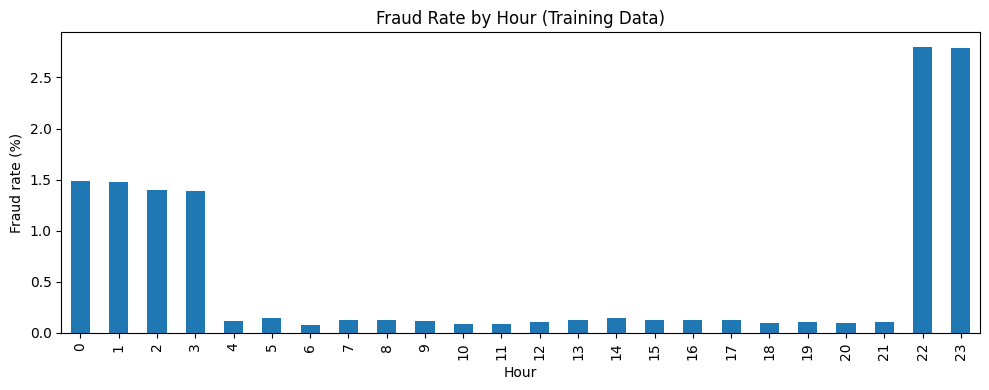

In [3]:
# Extract numeric features from the transaction time
df['hour'] = df['trans_date_trans_time'].dt.hour
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek  # 0 = Monday
df['month'] = df['trans_date_trans_time'].dt.month

# Customer age at the time of the transaction
df['age'] = ((df['trans_date_trans_time'] - df['dob']).dt.days / 365.25).round(1)

# Fraud rate by hour, training data only
train = df[df['is_train'] == 1]
(train.groupby('hour')['is_fraud'].mean() * 100).plot(kind='bar', figsize=(10, 4))
plt.title('Fraud Rate by Hour (Training Data)')
plt.xlabel('Hour')
plt.ylabel('Fraud rate (%)')
plt.tight_layout()
plt.show()

In [4]:
# 1 if the transaction happened at night (hours chosen from the chart above)
df['is_night'] = df['hour'].isin([22, 23, 0, 1, 2, 3]).astype(int)

**Observations:**

* **Peak Fraud Hours & `is_night` Selection:**
  The bar chart shows that fraud rate is concentrated in the late-night and early-morning hours. Peak fraud occurs at hours 22 and 23 (around 2.5%), followed by hours 0, 1, 2, and 3 (about 1.3% to 1.5%), while daytime hours remain well below 0.3%. Hours `[22, 23, 0, 1, 2, 3]` were selected for `is_night` to cleanly separate this high-risk nocturnal window.

* **Training-Only Data Usage (Data Leakage Prevention):**
  We calculated the hourly fraud rate strictly on the 2019 training split (`is_train == 1`). Deriving thresholds or feature rules from test data (2020) leaks future patterns into feature engineering, which inflates model evaluation and degrades real-world performance.

* **Feature Rationale:**
  * `hour`: Captures daily behavioral timing and isolates nocturnal risk windows.
  * `day_of_week`: Identifies spending differences between weekdays and weekends.
  * `month`: Required to monitor and evaluate model performance degradation month-by-month over time.
  * `age`: Captures customer demographic profiles and risk levels across different age groups.
  * `is_night`: Converts the non-linear nighttime spike into a clear binary signal.

## 3. Customer History Features — Rayan

In [5]:
# Sort each customer's transactions from oldest to newest
df = df.sort_values(['cc_num', 'trans_date_trans_time']).reset_index(drop=True)
g = df.groupby('cc_num')

# Hours since the customer's previous transaction (empty for the first one)
df['hours_since_prev'] = g['trans_date_trans_time'].diff().dt.total_seconds() / 3600

# Amount compared with the average of the customer's PREVIOUS amounts
prev_sum = g['amt'].cumsum() - df['amt']  # total of previous amounts
prev_count = g.cumcount()  # number of previous transactions
df['amt_to_customer_avg'] = df['amt'] / (prev_sum / prev_count)

# Number of the customer's transactions in the previous 24 hours
counts = df.set_index('trans_date_trans_time').groupby('cc_num')['amt'].rolling('24h').count()
df['txn_last_24h'] = (counts.values - 1).astype(int)  # -1 removes the current transaction

# Check: missing values should only be the first transaction of each customer
print(df[['hours_since_prev', 'amt_to_customer_avg']].isna().sum())
print("Number of customers:", df['cc_num'].nunique())

hours_since_prev       999
amt_to_customer_avg    999
dtype: int64
Number of customers: 999


**Note:** Each of the first two features has 999 missing values, one for every customer (999 customers). These are each customer's first transaction, which has no previous transaction to compare with. This is expected and will be filled in Task 6.

In [6]:
# Inspect the new features for one customer (first 10 transactions)
df[['cc_num', 'trans_date_trans_time', 'amt', 'hours_since_prev', 'amt_to_customer_avg', 'txn_last_24h']].head(10)

,cc_num,trans_date_trans_time,amt,hours_since_prev,amt_to_customer_avg,txn_last_24h
0,180011453250192,2019-01-03 01:39:04,90.37,NaN,NaN,0
1,180011453250192,2019-01-03 05:51:22,108.09,4.205000,1.196083,1
2,180011453250192,2019-01-03 14:48:47,447.52,8.956944,4.509926,2
3,180011453250192,2019-01-04 10:39:10,73.17,19.839722,0.339809,1
4,180011453250192,2019-01-04 12:48:21,47.55,2.153056,0.264479,2
5,180011453250192,2019-01-04 18:56:05,77.93,6.128889,0.508217,2
6,180011453250192,2019-01-05 06:29:32,131.60,11.557500,0.934847,3
7,180011453250192,2019-01-05 08:15:39,126.63,1.768611,0.907993,4
8,180011453250192,2019-01-05 14:26:27,50.52,6.180000,0.366465,3
9,180011453250192,2019-01-05 15:05:38,466.93,0.653056,3.643526,4


**Note (how `cumsum` and `cumcount` work):** `cumsum()` is a running total of the customer's amounts, so subtracting the current `amt` leaves only the total of the previous amounts. `cumcount()` numbers each customer's transactions starting from 0, so it equals the number of previous transactions. Example from the table: in row 2 the previous amounts are 90.37 and 108.09 (average 99.23), so 447.52 / 99.23 = 4.51, meaning this transaction is 4.5 times the customer's usual amount. Row 0 is the customer's first transaction, so the first two features are empty.

In [7]:
# Median of each new feature: legitimate (0) vs fraud (1), training data only
train = df[df['is_train'] == 1]
print(train.groupby('is_fraud')[['hours_since_prev', 'amt_to_customer_avg', 'txn_last_24h']].median())

          hours_since_prev  amt_to_customer_avg  txn_last_24h
is_fraud                                                     
0                 4.371389             0.661651           3.0
1                 1.330417             5.034918           4.0


**Results (training data, median):**

**`amt_to_customer_avg` shows the biggest difference.** A fraud transaction is about 5.03 times the customer's previous average amount, while a legitimate one is about 0.66 (below their usual amount). That is about 7.6 times higher for fraud.

**`hours_since_prev`:** Fraud happens about 1.33 hours after the customer's previous transaction, compared with 4.37 hours for legitimate transactions (about 3.3 times shorter). Fraud tends to come in quick bursts.

**`txn_last_24h`:** 4 transactions for fraud vs 3 for legitimate. The difference is small, so this is the weakest of the three features.

**Why we used previous transactions only:** If we used all of the customer's transactions, the average would include transactions that had not happened yet at that moment. This is data leakage from the future: the model would look better in the notebook than in real life, where we only know the past.

## 4. Distance Feature — Abdulmohsen

In [8]:
# Check coordinate columns before calculating the distance
coord_cols = ['lat', 'long', 'merch_lat', 'merch_long']
print(df[coord_cols].dtypes)
print('\nMissing values:')
print(df[coord_cols].isna().sum())

lat           float64
long          float64
merch_lat     float64
merch_long    float64
dtype: object

Missing values:
lat           0
long          0
merch_lat     0
merch_long    0
dtype: int64


In [9]:
# Convert customer and merchant coordinates from degrees to radians
lat1 = np.radians(df['lat'])
lon1 = np.radians(df['long'])
lat2 = np.radians(df['merch_lat'])
lon2 = np.radians(df['merch_long'])

# Calculate the Haversine distance in kilometers
a = (np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2)
a = np.clip(a, 0, 1)
df['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))

# Display summary statistics for the distance feature
print(df['distance_km'].describe())

count    1.852394e+06
mean     7.611173e+01
std      2.911697e+01
min      2.225452e-02
25%      5.532009e+01
50%      7.821638e+01
75%      9.850947e+01
max      1.521172e+02
Name: distance_km, dtype: float64


In [10]:
# Compare median distance for legitimate and fraudulent transactions in training data
train = df[df['is_train'] == 1]
print(train.groupby('is_fraud')['distance_km'].median())

is_fraud
0    78.237623
1    78.210791
Name: distance_km, dtype: float64


**Distance calculation:** `distance_km` measures the distance between the customer and merchant coordinates using the Haversine formula. It uses only the current row, so it does not introduce data leakage.

**Range check:** Distances range from approximately 0.022 km (22 meters) to 152.12 km. These values are non-negative and geographically plausible.

**Results (training data):** The median distance is 78.238 km for legitimate transactions and 78.211 km for fraudulent transactions. The difference is only about 0.027 km (27 meters), showing almost no separation by median. This comparison alone does not establish whether the feature will help the model.

**Why the coordinates will be dropped:** Following the task plan, `lat`, `long`, `merch_lat`, and `merch_long` will be dropped in Task 6. The new feature summarizes the distance between the two locations in one column, although it does not preserve their absolute locations.